# What does the market pay for? A neural-network fair-value model for Indian large caps (CMIE Prowess data)

**Advanced ML project, GIM. Full study on about 140 non-financial NIFTY 200 companies, 2017–2025.**

This notebook repeats the pilot study (20 companies, Screener data) on a dataset roughly ten times larger, taken from CMIE Prowess. It asks the same two questions:

1. **How much of a company's price-to-book ratio do its fundamentals explain?** A linear model, two tree ensembles and a tuned neural network are compared.
2. **Does the gap between actual and "fair" valuation predict the next 12 months' return?**

It also includes the neural network tuning study and two additions suggested by the pilot:
- a **test on companies the model has never seen**, which is the relevant test for valuing an unlisted business;
- a **10-seed average** of the network, reported next to the single-seed result.

### How to run on Google Colab
1. In Google Drive, create a project folder (any name), for example `MyDrive/Project2_Prowess/`.
2. Put this notebook in it, together with a sub-folder `data/prowess_raw/` holding the nine Prowess `.txt` files and `MANIFEST.csv`.
3. Open the notebook from Drive with Colab and choose **Runtime → Run all**. Allow Drive access when asked; the notebook finds the folder by itself. A CPU runtime is enough, and a full run takes roughly 20–30 minutes.
4. Choose **Run all** a second time. The last cell should print `IDENTICAL to previous run`.

No internet access is needed apart from Drive: every number comes from the frozen Prowess files, which are checked against their SHA-256 checksums before anything runs.

## 1. Settings and determinism

In [1]:
# These must be set BEFORE numpy is imported (local Jupyter). On Colab, numpy is already loaded,
# so the thread limit is also enforced at run time in the next cell.
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[_v] = "1"
os.environ["PYTHONHASHSEED"] = "0"

import sys, importlib.util
from pathlib import Path

SEED = 42
PROJECT_OVERRIDE = ""   # optional: full path to the project folder if it isn't found automatically
MARKER = Path("data") / "prowess_raw" / "MANIFEST.csv"

def find_project():
    """Locate the project folder: Google Drive on Colab, the notebook's own folder locally."""
    if PROJECT_OVERRIDE:
        return Path(PROJECT_OVERRIDE)
    if importlib.util.find_spec("google.colab") is not None:
        from google.colab import drive
        drive.mount("/content/drive")
        root = Path("/content/drive/MyDrive")
        hits = []
        for depth in range(0, 7):   # search up to 6 folders deep for data/prowess_raw/MANIFEST.csv
            hits += sorted(root.glob("/".join(["*"] * depth + list(MARKER.parts))))
            if hits:
                break
        projects = [h.parents[2] for h in hits]
        assert projects, ("Could not find a folder containing data/prowess_raw/MANIFEST.csv in your Google Drive. "
                          "Set PROJECT_OVERRIDE above to the folder's path, e.g. '/content/drive/MyDrive/Project2_Prowess'.")
        with_nb = [p for p in projects if (p / "Fair_Value_NN_Prowess.ipynb").exists()]
        return (with_nb or projects)[0]
    return Path.cwd()

PROJECT = find_project()
os.chdir(PROJECT)
RAW = PROJECT / "data" / "prowess_raw"
OUT = PROJECT / "outputs"
TAB, FIG = OUT / "tables", OUT / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)

FIRST_YEAR, LAST_YEAR = 2017, 2025      # formation years (30 June); Prowess abridged history supports 3-yr ratios from 2017
TEST_YEARS = list(range(2019, 2026))    # walk-forward test years; training always uses earlier years only
BACKTEST_YEARS = list(range(2019, 2026))  # each needs 12 months of prices after formation (to June 2026)
MIN_MCAP_CR = 5000                      # keep companies worth at least Rs 5,000 crore on the formation date
N_VAL_YEARS = 3                         # tuning: validate on the last 3 training years (expanding window)
N_TRIALS_WF = 30                        # MLP random-search trials inside each walk-forward step
N_TRIALS_FULL = 60                      # MLP trials for the full-sample tuning study
N_TRIALS_ABL = 15                       # MLP trials per ablation variant
SEEDS = list(range(10))
print("Project folder:", PROJECT)
print("Running on:", "Google Colab" if "google.colab" in sys.modules else "local machine")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/GIM/AMLBT_project/Project2/Prowess_version
Running on: Google Colab


In [2]:
import hashlib, io, json, platform, random, sys, warnings
import numpy as np
import pandas as pd
import openpyxl
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy, xgboost
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import ParameterSampler, ParameterGrid
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor

from threadpoolctl import threadpool_limits
threadpool_limits(1)   # one thread for all maths libraries -> identical results on every run
warnings.filterwarnings("ignore", category=ConvergenceWarning)
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

# Chart style: thin marks, recessive axes, fixed colour order.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#6250d6",
     "grey": "#8a8984", "ink": "#0b0b0b", "ink2": "#52514e"}
MODEL_COLORS = {"Ridge": C["blue"], "RandomForest": C["orange"], "XGBoost": C["aqua"],
                "MLP": C["violet"], "Naive (last year)": C["grey"]}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c3", "axes.labelcolor": C["ink2"],
                     "xtick.color": C["ink2"], "ytick.color": C["ink2"],
                     "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
                     "axes.titleweight": "bold", "axes.titlesize": 11,
                     "svg.hashsalt": "fixed"})

def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})

versions = {"python": sys.version.split()[0], "platform": platform.platform(),
            "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "openpyxl": openpyxl.__version__}
(OUT / "environment.json").write_text(json.dumps(versions, indent=2))
versions

{'python': '3.13.18',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'numpy': '2.4.6',
 'pandas': '2.2.3',
 'scikit-learn': '1.6.1',
 'xgboost': '3.4.1',
 'scipy': '1.16.3',
 'matplotlib': '3.10.0',
 'openpyxl': '3.1.5'}

## 2. Data integrity check

Each Prowess export is checked against the SHA-256 checksum recorded in `data/prowess_raw/MANIFEST.csv` when it was downloaded on campus. If any file has changed, the notebook stops here rather than produce different numbers.

In [3]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

manifest = pd.read_csv(RAW / "MANIFEST.csv")
bad = [r.file for r in manifest.itertuples() if sha256(RAW / r.file) != r.sha256]
assert not bad, f"These raw files changed since download: {bad}"
print(f"All {len(manifest)} Prowess files match their recorded checksums.")
manifest[["file", "description"]]

All 9 Prowess files match their recorded checksums.


,file,description
0,prowess_C_2010_2018.txt,"Abridged Annual Financials, consolidated, FY20..."
1,prowess_C_2019_2026.txt,"Abridged Annual Financials, consolidated, FY20..."
2,prowess_S_2010_2018.txt,"Abridged Annual Financials, standalone, FY2011..."
3,prowess_S_2019_2026.txt,"Abridged Annual Financials, standalone, FY2019..."
4,prowess_identity.txt,"Identity: industry group, NIC name, ISIN, NSE ..."
5,prowess_px_adjclose_monthly.txt,"NSE adjusted closing price, monthly (last trad..."
6,prowess_px_mcap_monthly.txt,"NSE market capitalisation, monthly AVERAGE (Rs..."
7,prowess_px_nifty_monthly.txt,"NIFTY 50 closing index, monthly (same value on..."
8,prowess_px_totret_monthly.txt,"NSE total returns (%), monthly, Jan 2010-Oct 2026"


## 3. Read the Prowess exports

Prowess TXT exports are pipe-separated and wide: one row per company, and one block of columns per year (or month). A single reader turns every file into a long table of *company, period, field, value*.

**Accounts.** Prowess *Abridged Annual Financials* were downloaded on both a consolidated (C) and a standalone (S) basis. For each company-year, consolidated figures are used where they exist, otherwise standalone. Ratios that need history (ROE on average equity, 3-year sales growth, ROE stability) are computed within one basis, so a change of basis can't create a false jump. Consolidated statements only became compulsory from FY2015 under the Companies Act, 2013, so when the consolidated history is too short, the standalone growth rate and ROE stability are used instead.

In [4]:
def read_prowess(path):
    """Read a Prowess TXT export into long format: code, name, slot, field, value (text)."""
    lines = Path(path).read_text(encoding="utf-8", errors="replace").splitlines()
    slot_i = next(i for i, l in enumerate(lines) if l.startswith("Slot Date|"))
    head_i = next(i for i, l in enumerate(lines) if l.startswith("Company Code|"))
    slots, names = lines[slot_i].split("|"), lines[head_i].split("|")
    recs = []
    for l in lines[head_i + 1:]:
        if not l.strip():
            continue
        p = l.split("|")
        for j in range(2, min(len(p), len(names))):
            if p[j] != "":
                recs.append((p[0], p[1], slots[j], names[j], p[j]))
    return pd.DataFrame(recs, columns=["code", "name", "slot", "field", "value"])

FIELD_MAP = {"Year": "report_date", "Months": "months", "Revenue From Operations": "sales",
             "Other Income": "other_income", "Finance Cost": "interest",
             "Depreciation & Amortisation": "depreciation", "Total profit before tax": "pbt",
             "Total profit (loss) for period": "net_profit", "Share Capital": "equity_capital",
             "Reserves & Surplus": "reserves", "Minority interest": "minority",
             "Long term Borrowings": "lt_borrowings", "Short Term Borrowings": "st_borrowings",
             "Assets": "total_assets", "Cash & Bank Balances": "cash",
             "Net cash flow from operating activities": "cfo", "Dividend Paid": "dividend_paid",
             "Net worth": "net_worth", "Operating Profit": "operating_profit"}

def read_fin(basis):
    parts = [read_prowess(RAW / f"prowess_{basis}_{a}.txt") for a in ("2010_2018", "2019_2026")]
    d = pd.concat(parts, ignore_index=True)
    d["field"] = d["field"].map(FIELD_MAP)
    w = (d.pivot_table(index=["code", "name", "slot"], columns="field", values="value", aggfunc="first")
           .reset_index())
    w["report_date"] = pd.to_datetime(w["report_date"], format="%d-%m-%Y", errors="coerce")
    num = [c for c in FIELD_MAP.values() if c != "report_date"]
    w[num] = w[num].apply(pd.to_numeric, errors="coerce")
    w["basis"] = basis
    return w.dropna(subset=["report_date", "sales"])

fin_all = pd.concat([read_fin("C"), read_fin("S")], ignore_index=True)
print(f"{fin_all['code'].nunique()} companies; years ending "
      f"{fin_all['report_date'].min().date()} to {fin_all['report_date'].max().date()}")
fin_all.groupby("basis").agg(companies=("code", "nunique"), company_years=("code", "size"),
                             first_year=("report_date", "min")).T

147 companies; years ending 2011-03-31 to 2026-03-31


basis,C,S
companies,139,147
company_years,1560,1743
first_year,2012-03-31 00:00:00,2011-03-31 00:00:00


### Align each financial year to a formation date

Annual results are published within about two months of the year end, so each year's accounts are matched to the **first 30 June at least 60 days after the year end**. Accounting periods that aren't 12 months long (a change of year end) have their income and cash-flow figures scaled to 12 months.

In [5]:
def formation_year(report_date):
    avail = report_date + pd.Timedelta(days=60)
    return avail.year if avail <= pd.Timestamp(year=avail.year, month=6, day=30) else avail.year + 1

fa = fin_all.copy()
fa["year"] = fa["report_date"].map(formation_year)
fa = (fa.sort_values(["code", "basis", "report_date"], kind="stable")
        .drop_duplicates(["code", "basis", "year"], keep="last").reset_index(drop=True))
FLOWS = ["sales", "other_income", "interest", "depreciation", "pbt", "net_profit", "cfo",
         "dividend_paid", "operating_profit"]
fa["months"] = fa["months"].fillna(12).clip(lower=3)
fa[FLOWS] = fa[FLOWS].mul(12 / fa["months"], axis=0)
fa["dividend"] = fa["dividend_paid"].abs()
fa["borrowings"] = fa[["lt_borrowings", "st_borrowings"]].sum(axis=1, min_count=1)
fa["book"] = fa["net_worth"]

# history-based ratios, computed within each basis (consecutive formation years only)
gb = fa.groupby(["code", "basis"])
consecutive = lambda k: fa["year"] - gb["year"].shift(k) == k
fa["roe"] = (fa["net_profit"] / ((fa["book"] + gb["book"].shift(1)) / 2)).where(consecutive(1))
base3 = gb["sales"].shift(3)
fa["sales_cagr_3y"] = (((fa["sales"] / base3.where(base3 > 0)) ** (1 / 3) - 1)).where(consecutive(3))
fa["roe_volatility_3y"] = fa.groupby(["code", "basis"])["roe"].transform(lambda s: s.rolling(3).std())

# one row per company-year: consolidated if available, else standalone
fin = (fa.sort_values(["code", "year", "basis"], kind="stable")      # 'C' sorts before 'S'
         .drop_duplicates(["code", "year"], keep="first").reset_index(drop=True))
s_hist = fa[fa["basis"] == "S"].set_index(["code", "year"])[["sales_cagr_3y", "roe_volatility_3y"]]
fallback = s_hist.reindex(pd.MultiIndex.from_frame(fin[["code", "year"]])).reset_index(drop=True)
for c in ["sales_cagr_3y", "roe_volatility_3y"]:
    fin[c] = fin[c].fillna(fallback[c])
print(f"{len(fin)} company-years; consolidated {int((fin['basis'] == 'C').sum())}, "
      f"standalone {int((fin['basis'] == 'S').sum())}; periods not 12 months: {int((fin['months'] != 12).sum())}")

1740 company-years; consolidated 1556, standalone 184; periods not 12 months: 13


### Company identifiers and sectors

The NSE industry label (66 distinct values) is grouped into 12 broad sectors. Two companies that Prowess files as non-financial but whose business is financial (a stock broker and a payments fintech) are excluded, as banks and other lenders are.

In [6]:
lines = (RAW / "prowess_identity.txt").read_text(encoding="utf-8").splitlines()
ident = pd.DataFrame([l.split("|") for l in lines[2:] if l.strip()], columns=lines[1].split("|"))
ident = ident.rename(columns={"Company Code": "code", "NSE Basic Industry classification": "nse_industry",
                              "NSE symbol": "symbol", "Industry group": "prowess_industry"})
SECTOR_RULES = {
    "IT": ["Computers - Software", "Software Products"],
    "Pharma & healthcare": ["Pharmaceuticals", "Hospital"],
    "Auto": ["Auto Components", "2/3 Wheelers", "Passenger Cars", "Commercial Vehicles", "Tyres"],
    "Capital goods": ["Heavy Electrical", "Other Electrical", "Aerospace", "Ship Building", "Cables",
                      "Civil Construction", "Compressors", "Plastic Products"],
    "Real estate": ["Residential, Commercial"],
    "Oil & gas": ["Refineries", "Oil Exploration", "LPG/CNG", "Gas Transmission"],
    "Power": ["Power Generation", "Integrated Power", "Power - Transmission"],
    "Metals & mining": ["Iron & Steel", "Aluminium", "Copper", "Zinc", "Diversified Metals",
                        "Industrial Minerals", "Trading - Minerals"],
    "Materials & chemicals": ["Cement", "Specialty Chemicals", "Pesticides", "Explosives"],
    "FMCG": ["Personal Care", "Packaged Foods", "Diversified FMCG", "Edible Oil", "Breweries",
             "Cigarettes", "Tea & Coffee", "Other Beverages"],
    "Consumer discretionary": ["E-Retail", "Diversified Retail", "Speciality Retail", "Internet & Catalogue",
                               "Household Appliances", "Consumer Electronics", "Gems, Jewellery",
                               "Garments", "Hotels", "Tour, Travel", "Restaurants", "Paints"],
    "Telecom & transport": ["Telecom", "Port", "Airport", "Logistics", "Airline"],
}
EXCLUDE_INDUSTRIES = ["Stockbroking", "Financial Technology"]

def sector_of(label):
    for sec, keys in SECTOR_RULES.items():
        if any(k.lower() in label.lower() for k in keys):
            return sec
    return "Other"

ident["sector"] = [sector_of(a or b) for a, b in zip(ident["nse_industry"], ident["prowess_industry"])]
ident["exclude"] = ident["nse_industry"].map(lambda s: any(k in s for k in EXCLUDE_INDUSTRIES))
print("Excluded:", ident.loc[ident["exclude"], "Company Name"].tolist())
ident.groupby("sector").size().rename("companies").sort_values(ascending=False).to_frame().T

Excluded: ['Billionbrains Garage Ventures Ltd.', 'One 97 Communications Ltd.']


sector,Capital goods,Consumer discretionary,Auto,Pharma & healthcare,FMCG,Metals & mining,IT,Oil & gas,Materials & chemicals,Telecom & transport,Power,Real estate,Other
companies,21,20,16,15,14,13,10,8,8,8,7,5,2


## 4. Monthly prices

Prowess gives month-end **adjusted closing prices** (corrected for splits, bonuses and rights issues), the month's **average market capitalisation**, and the NIFTY 50 index. Returns are measured from adjusted prices, so they exclude dividends; for these companies that understates returns by roughly 1–2% a year and affects all stocks similarly. The Prowess "total returns" series was downloaded too, but on a monthly setting it holds the last day's return, so it is not used.

In [7]:
def read_monthly(fname, col):
    d = read_prowess(RAW / fname)
    d["month"] = pd.to_datetime(d["slot"], format="%d %b %Y")
    d[col] = pd.to_numeric(d["value"], errors="coerce")
    return d[["code", "month", col]]

px = read_monthly("prowess_px_adjclose_monthly.txt", "adj_close").merge(
     read_monthly("prowess_px_mcap_monthly.txt", "mcap_avg"), on=["code", "month"], how="outer")
nifty = read_monthly("prowess_px_nifty_monthly.txt", "nifty").groupby("month")["nifty"].first().sort_index()
adjw = px.pivot(index="month", columns="code", values="adj_close").sort_index()
mcapw = px.pivot(index="month", columns="code", values="mcap_avg").sort_index()
logret, nret = np.log(adjw).diff(), np.log(nifty).diff()
print(f"Prices: {adjw.shape[1]} companies, {adjw.index.min():%b %Y} to {adjw.index.max():%b %Y} "
      f"({adjw.shape[0]} months)")

Prices: 147 companies, Jan 2010 to Oct 2026 (202 months)


## 5. Build the modelling table

**Target:** log(price-to-book) on 30 June, using June's average market capitalisation and the latest net worth.

**Fundamental inputs:** return on equity, operating margin, 3-year sales growth, debt-to-equity, interest cover, asset turnover, dividend payout, cash conversion, ROE stability, size and sector. Each ratio is capped at fixed, economically sensible limits; the caps are set in advance rather than estimated from the data.

**Market inputs:** 12-month momentum (log), 24-month volatility and 36-month beta to the NIFTY 50, all measured up to the formation date.

**Forward return (backtest only, never an input):** the price return over the 12 months after formation.

**Sample rules:**
- formation years 2017–2025 (Prowess's abridged statements are sparse before FY2014, so 3-year ratios are only available from 2017);
- a market cap of at least ₹5,000 crore at formation, so that every observation was a large company at the time and not only today;
- P/B between 0.05 and 200, which removes a handful of companies with near-zero or negative book value.

In [8]:
rows = []
for r in fin.itertuples():
    m = pd.Timestamp(year=r.year, month=6, day=30)
    if r.code not in adjw.columns or m not in adjw.index:
        rows.append({}); continue
    i = adjw.index.get_loc(m)
    a = adjw[r.code]
    rec = {"mcap_cr": mcapw.at[m, r.code]}
    if i >= 12 and pd.notna(a.iloc[i - 12]):
        rec["momentum_12m"] = a.iloc[i] / a.iloc[i - 12] - 1
    win = logret[r.code].iloc[max(0, i - 23):i + 1].dropna()
    if len(win) >= 18:
        rec["volatility_24m"] = win.std() * np.sqrt(12)
    wb = pd.concat([logret[r.code], nret], axis=1).iloc[max(0, i - 35):i + 1].dropna()
    if len(wb) >= 24:
        rec["beta_36m"] = np.cov(wb.iloc[:, 0], wb.iloc[:, 1])[0, 1] / wb.iloc[:, 1].var()
    if i + 12 < len(adjw):
        rec["fwd_return_12m"] = a.iloc[i + 12] / a.iloc[i] - 1
        rec["nifty_fwd_12m"] = nifty.iloc[i + 12] / nifty.iloc[i] - 1
    rows.append(rec)
fin = pd.concat([fin.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
fin = fin.merge(ident[["code", "symbol", "nse_industry", "sector", "exclude"]], on="code", how="left")
fin["ticker"] = fin["symbol"].where(fin["symbol"].fillna("") != "", fin["name"])

fin["op_margin"] = (fin["pbt"] + fin["interest"] + fin["depreciation"] - fin["other_income"]) / fin["sales"]
fin["debt_equity"] = fin["borrowings"] / fin["book"]
cover = (fin["pbt"] + fin["interest"]) / fin["interest"].where(fin["interest"] > 0)
fin["log_interest_cover"] = np.log1p(cover.clip(0, 100).fillna(100))
fin["asset_turnover"] = fin["sales"] / fin["total_assets"]
fin["payout"] = (fin["dividend"] / fin["net_profit"].where(fin["net_profit"] > 0)).clip(0, 1.5)
fin["cash_conversion"] = (fin["cfo"] / fin["net_profit"].where(fin["net_profit"] > 0)).clip(-1, 3)
fin["log_sales"] = np.log(fin["sales"].where(fin["sales"] > 0))
fin["log_momentum_12m"] = np.log1p(fin["momentum_12m"])
CAPS = {"roe": (-1, 1.5), "op_margin": (-1, 1), "sales_cagr_3y": (-0.5, 2), "debt_equity": (0, 10),
        "asset_turnover": (0, 5), "roe_volatility_3y": (0, 1), "log_momentum_12m": (-2, 2)}
for c, (lo, hi) in CAPS.items():
    fin[c] = fin[c].clip(lo, hi)
pb = fin["mcap_cr"] / fin["book"]
fin["log_pb"] = np.log(pb.where(fin["book"] > 0))
gl = fin.groupby("code")
fin["log_pb_last_year"] = gl["log_pb"].shift(1).where(fin["year"] - gl["year"].shift(1) == 1)

FUND_FEATS = ["roe", "op_margin", "sales_cagr_3y", "debt_equity", "log_interest_cover",
              "asset_turnover", "payout", "cash_conversion", "roe_volatility_3y", "log_sales"]
MKT_FEATS = ["log_momentum_12m", "volatility_24m", "beta_36m"]
SECTORS = sorted(ident.loc[~ident["exclude"], "sector"].unique())
SECTOR_FEATS = [f"sector_{s}" for s in SECTORS]
for s in SECTORS:
    fin[f"sector_{s}"] = (fin["sector"] == s).astype(float)
FEATURE_SETS = {"Fundamentals only": FUND_FEATS + SECTOR_FEATS,
                "Market only": MKT_FEATS,
                "Fundamentals + market": FUND_FEATS + SECTOR_FEATS + MKT_FEATS}
ALL_FEATS = FEATURE_SETS["Fundamentals + market"]

keep = ((~fin["exclude"].fillna(False).astype(bool)) & (fin["mcap_cr"] >= MIN_MCAP_CR)
        & fin["log_pb"].notna() & pb.between(0.05, 200) & fin["roe"].notna()
        & fin["year"].between(FIRST_YEAR, LAST_YEAR))
data = fin[keep].sort_values(["year", "ticker"], kind="stable").reset_index(drop=True)
save_table(data[["code", "ticker", "name", "year", "sector", "basis", "log_pb"] + FUND_FEATS + MKT_FEATS +
                ["fwd_return_12m", "nifty_fwd_12m"]], "modelling_table")
print(f"Modelling table: {len(data)} company-years, {data['code'].nunique()} companies, "
      f"years {data['year'].min()}-{data['year'].max()}")
data.groupby("year").size().rename("companies").to_frame().T

Modelling table: 1102 company-years, 141 companies, years 2017-2025


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
companies,111,112,112,114,123,126,133,132,139


In [9]:
desc = data[["log_pb"] + FUND_FEATS + MKT_FEATS].describe().T[["count", "mean", "std", "min", "50%", "max"]]
save_table(desc.reset_index(names="variable"), "descriptive_stats")
desc

,count,mean,std,min,50%,max
log_pb,1102.0,1.593,1.020,-1.196e+00,1.560,4.762
roe,1102.0,0.179,0.194,-1.000e+00,0.167,1.500
op_margin,1102.0,0.209,0.155,-5.215e-01,0.183,1.000
sales_cagr_3y,1089.0,0.126,0.152,-2.732e-01,0.106,2.000
debt_equity,1102.0,0.600,1.159,0.000e+00,0.192,10.000
log_interest_cover,1102.0,2.658,1.302,0.000e+00,2.565,4.615
asset_turnover,1102.0,0.916,0.606,6.662e-02,0.775,4.484
payout,985.0,0.371,0.333,0.000e+00,0.284,1.500
cash_conversion,1042.0,1.378,0.894,-1.000e+00,1.250,3.000
roe_volatility_3y,1090.0,0.074,0.139,8.965e-05,0.036,1.000


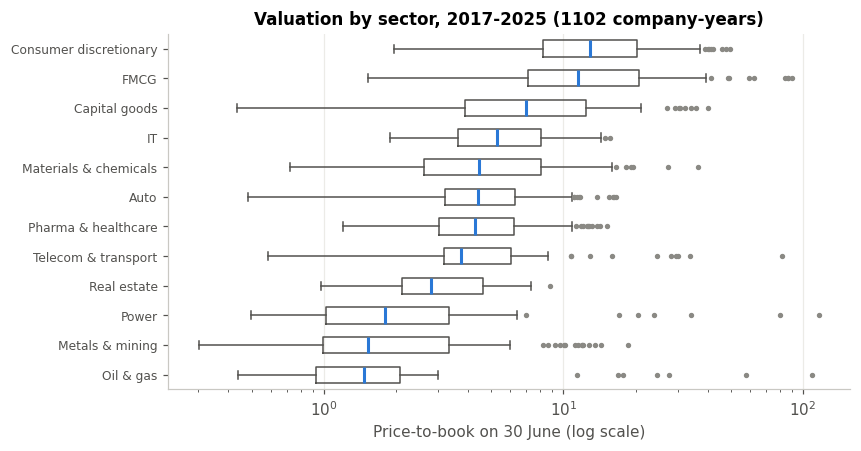

In [10]:
order = data.groupby("sector")["log_pb"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.2))
_horiz = ({"orientation": "horizontal"} if tuple(int(x) for x in matplotlib.__version__.split(".")[:2]) >= (3, 10)
          else {"vert": False})
ax.boxplot([np.exp(data.loc[data["sector"] == s, "log_pb"]) for s in order], **_horiz,
           tick_labels=order, widths=0.55, medianprops={"color": C["blue"], "lw": 2},
           boxprops={"color": C["ink2"]}, whiskerprops={"color": C["ink2"]}, capprops={"color": C["ink2"]},
           flierprops={"markersize": 2.5, "markerfacecolor": C["grey"], "markeredgecolor": C["grey"]})
ax.set_xscale("log"); ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Price-to-book on 30 June (log scale)")
ax.set_title(f"Valuation by sector, {FIRST_YEAR}-{LAST_YEAR} ({len(data)} company-years)")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig1_pb_by_sector"); plt.show()

## 6. Models and the tuning procedure

Every model sits in the same pipeline: median imputation → standardisation → estimator.

| Model | Role | Hyperparameters searched |
|---|---|---|
| Ridge regression | Classical linear valuation regression | L2 penalty (7 values) |
| Random Forest | Bagged tree ensemble | features per split, leaf size (4 combinations) |
| XGBoost | Boosted tree ensemble | depth, learning rate, number of trees (8 combinations) |
| **MLP (neural network)** | The model under study | architecture, activation, L2 penalty, optimiser, learning rate (seeded random search) |
| Naive benchmark | Last year's own P/B | none |

**Tuning is always done on past years only.** Within each training set, every candidate setting is scored on the *last three training years*, one at a time, each time training only on the years before it (expanding-window validation). This respects time order and keeps the run time reasonable. The winning setting is then refit on all training years and used to predict the test year. Every random draw uses a fixed seed and every model runs on a single thread.

In [11]:
from scipy.stats import loguniform

MLP_SPACE = {
    "hidden_layer_sizes": [(4,), (8,), (16,), (32,), (8, 4), (16, 8), (32, 16)],
    "activation": ["relu", "tanh"],
    "alpha": loguniform(1e-3, 30),
    "solver": ["lbfgs", "adam"],
    "learning_rate_init": loguniform(1e-3, 3e-2),
}
GRIDS = {
    "Ridge": list(ParameterGrid({"alpha": [0.01, 0.1, 1, 3, 10, 30, 100]})),
    "RandomForest": list(ParameterGrid({"max_features": [0.33, 0.66], "min_samples_leaf": [2, 5]})),
    "XGBoost": list(ParameterGrid({"max_depth": [2, 3], "learning_rate": [0.03, 0.1],
                                   "n_estimators": [200, 500]})),
}

def mlp_candidates(n, seed=SEED):
    out = []
    for p in ParameterSampler(MLP_SPACE, n_iter=n, random_state=seed):
        p = dict(p)
        p["alpha"] = float(p["alpha"]); p["learning_rate_init"] = float(p["learning_rate_init"])
        out.append(p)
    return out

def build(name, params, seed=SEED):
    if name == "Ridge":
        est = Ridge(**params)
    elif name == "RandomForest":
        est = RandomForestRegressor(n_estimators=300, random_state=seed, n_jobs=1, **params)
    elif name == "XGBoost":
        est = XGBRegressor(subsample=0.8, colsample_bytree=0.8, min_child_weight=3, reg_lambda=1.0,
                           tree_method="hist", n_jobs=1, random_state=seed, verbosity=0, **params)
    elif name == "MLP":
        est = MLPRegressor(max_iter=2000 if params["solver"] == "lbfgs" else 1000,
                           random_state=seed, **params)
    else:
        raise ValueError(name)
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), est)

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def cv_rmse(name, params, train, feats, seed=SEED):
    """Expanding-window validation RMSE: validate on each of the last N_VAL_YEARS training years,
    training only on the years before it."""
    years = sorted(train["year"].unique())
    errs = []
    for yr in years[-min(N_VAL_YEARS, len(years) - 1):]:
        tr, va = train[train["year"] < yr], train[train["year"] == yr]
        m = build(name, params, seed).fit(tr[feats], tr["log_pb"])
        errs.append((va["log_pb"].to_numpy() - m.predict(va[feats])) ** 2)
    return float(np.sqrt(np.mean(np.concatenate(errs))))

def tune(name, train, feats, n_trials=N_TRIALS_WF, seed=SEED):
    cands = mlp_candidates(n_trials, seed) if name == "MLP" else GRIDS[name]
    log = [{**p, "cv_rmse": cv_rmse(name, p, train, feats, seed)} for p in cands]
    log = pd.DataFrame(log)
    best = cands[int(np.argmin(log["cv_rmse"].to_numpy()))]   # first minimum -> deterministic tie-break
    return best, log

print(f"MLP search draws {N_TRIALS_WF} settings per step; first three:")
pd.DataFrame(mlp_candidates(3))

MLP search draws 30 settings per step; first three:


,activation,alpha,hidden_layer_sizes,learning_rate_init,solver
0,relu,3.683,"(32, 16)",0.012,lbfgs
1,relu,0.005,"(16,)",0.001,lbfgs
2,tanh,0.031,"(16,)",0.001,adam


## 7. Walk-forward evaluation: how well does each model explain valuations?

For each test year from 2019 to 2025, every model is tuned and trained only on earlier years, then predicts that year's P/B. The reported measures are:

- **Out-of-sample R²:** the share of the variation in log P/B the model explains, compared with simply predicting the training-years average.
- **RMSE:** the typical error in log P/B. An RMSE of 0.30 means the model is typically about 35% off in P/B terms.
- **Rank correlation:** within each year, whether the model ranks companies from cheapest to most expensive in the right order.

In [12]:
MODELS = ["Ridge", "RandomForest", "XGBoost", "MLP"]

def walk_forward(feats, models=MODELS, n_trials=N_TRIALS_WF, seed=SEED, fixed_params=None):
    preds, chosen = [], {}
    for yr in TEST_YEARS:
        train, test = data[data["year"] < yr], data[data["year"] == yr]
        out = test[["ticker", "year", "log_pb", "log_pb_last_year", "fwd_return_12m", "nifty_fwd_12m"]].copy()
        for name in models:
            if fixed_params is not None:
                params = fixed_params[(name, yr)]
            else:
                params, _ = tune(name, train, feats, n_trials, seed)
            chosen[(name, yr)] = params
            out[name] = build(name, params, seed).fit(train[feats], train["log_pb"]).predict(test[feats])
        out["train_mean"] = train["log_pb"].mean()
        preds.append(out)
    return pd.concat(preds, ignore_index=True), chosen

def score(pred, cols):
    rows = []
    for c in cols:
        d = pred.dropna(subset=[c])
        sse = ((d["log_pb"] - d[c]) ** 2).sum()
        sst = ((d["log_pb"] - d["train_mean"]) ** 2).sum()
        rank = d.groupby("year")[["log_pb", c]].apply(
            lambda x: stats.spearmanr(x["log_pb"], x[c]).statistic).mean()
        rows.append({"model": c, "oos_r2": 1 - sse / sst, "rmse": rmse(d["log_pb"], d[c]),
                     "mean_rank_corr": rank, "n": len(d)})
    return pd.DataFrame(rows)

wf_pred, wf_params = walk_forward(ALL_FEATS)
wf_pred["Naive (last year)"] = wf_pred["log_pb_last_year"]
wf_scores = score(wf_pred, MODELS + ["Naive (last year)"])
save_table(wf_scores, "table1_walkforward_scores")
save_table(wf_pred, "walkforward_predictions")
wf_scores

,model,oos_r2,rmse,mean_rank_corr,n
0,Ridge,0.564,0.696,0.787,879
1,RandomForest,0.641,0.632,0.826,879
2,XGBoost,0.683,0.594,0.843,879
3,MLP,0.701,0.577,0.842,879
4,Naive (last year),0.812,0.455,0.931,860


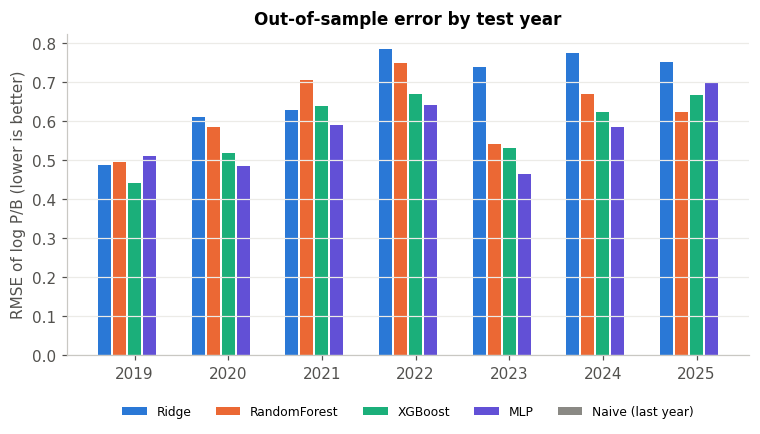

model,Ridge,RandomForest,XGBoost,MLP,Naive (last year)
year,,,,,
2019,0.489,0.495,0.440,0.511,NaN
2020,0.609,0.586,0.517,0.485,NaN
2021,0.629,0.706,0.640,0.590,NaN
2022,0.785,0.748,0.670,0.640,NaN
2023,0.738,0.541,0.531,0.465,NaN
2024,0.775,0.671,0.623,0.584,NaN
2025,0.752,0.623,0.668,0.699,NaN


In [13]:
by_year = []
for yr, d in wf_pred.groupby("year"):
    for c in MODELS + ["Naive (last year)"]:
        by_year.append({"year": yr, "model": c, "rmse": rmse(d["log_pb"], d[c])})
by_year = pd.DataFrame(by_year).pivot(index="year", columns="model", values="rmse")[MODELS + ["Naive (last year)"]]
save_table(by_year.reset_index(), "table2_rmse_by_year")

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.16
for k, c in enumerate(by_year.columns):
    ax.bar(np.arange(len(by_year)) + (k - 2) * w, by_year[c], width=w - 0.02,
           color=MODEL_COLORS[c], label=c)
ax.set_xticks(range(len(by_year)), by_year.index)
ax.set_ylabel("RMSE of log P/B (lower is better)")
ax.set_title("Out-of-sample error by test year")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
save_fig(fig, "fig2_rmse_by_year"); plt.show()
by_year

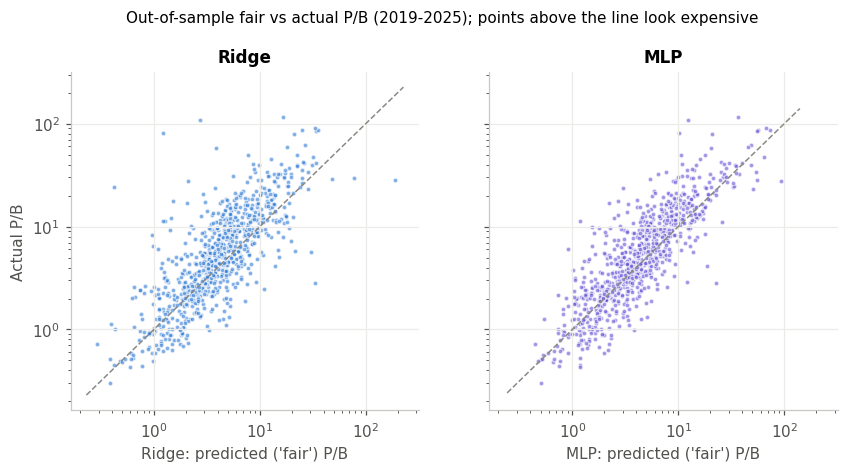

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, c in zip(axes, ["Ridge", "MLP"]):
    ax.scatter(np.exp(wf_pred[c]), np.exp(wf_pred["log_pb"]), s=9, alpha=0.6, color=MODEL_COLORS[c],
               edgecolor="white", linewidth=0.8)
    lim = [np.exp(wf_pred[["log_pb", c]].min().min()) * 0.8, np.exp(wf_pred[["log_pb", c]].max().max()) * 1.2]
    ax.plot(lim, lim, color=C["grey"], lw=1, ls="--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{c}: predicted ('fair') P/B"); ax.set_title(c)
axes[0].set_ylabel("Actual P/B")
fig.suptitle(f"Out-of-sample fair vs actual P/B ({TEST_YEARS[0]}-{TEST_YEARS[-1]}); points above the line look expensive",
             fontsize=10, y=1.02)
save_fig(fig, "fig3_fair_vs_actual"); plt.show()

## 8. Neural network tuning study

### 8a. Which hyperparameters matter?

Here the full random search is run once on the whole sample, validating on its last three years. This search is **descriptive**: it shows how sensitive the network is to each setting. The walk-forward results above never see it.

In [15]:
best_full, search_log = tune("MLP", data, ALL_FEATS, n_trials=N_TRIALS_FULL)
search_log["architecture"] = search_log["hidden_layer_sizes"].map(lambda h: "-".join(map(str, h)))
search_log = search_log.sort_values("cv_rmse", kind="stable").reset_index(drop=True)
save_table(search_log.drop(columns="hidden_layer_sizes"), "table3_mlp_search_log")

ridge_full, ridge_log = tune("Ridge", data, ALL_FEATS)
print("Best MLP setting:", best_full)
print(f"Best MLP CV RMSE {search_log['cv_rmse'].iloc[0]:.3f}  |  "
      f"Ridge CV RMSE {ridge_log['cv_rmse'].min():.3f}  |  "
      f"Median MLP trial {search_log['cv_rmse'].median():.3f}")
search_log.drop(columns="hidden_layer_sizes").head(10)

Best MLP setting: {'activation': 'relu', 'alpha': 7.080394772917343, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.0017860137889397097, 'solver': 'lbfgs'}
Best MLP CV RMSE 0.587  |  Ridge CV RMSE 0.750  |  Median MLP trial 0.673


,activation,alpha,learning_rate_init,solver,cv_rmse,architecture
0,relu,7.080,0.002,lbfgs,0.587,32-16
1,relu,7.138,0.002,lbfgs,0.590,32-16
2,relu,3.683,0.012,lbfgs,0.592,32-16
3,relu,1.240,0.024,lbfgs,0.603,32-16
4,tanh,0.480,0.002,adam,0.630,16
5,relu,0.020,0.004,adam,0.631,16
6,relu,0.064,0.027,adam,0.631,16-8
7,tanh,1.304,0.009,adam,0.638,32-16
8,relu,0.033,0.011,adam,0.638,16
9,tanh,6.320,0.007,lbfgs,0.639,8-4


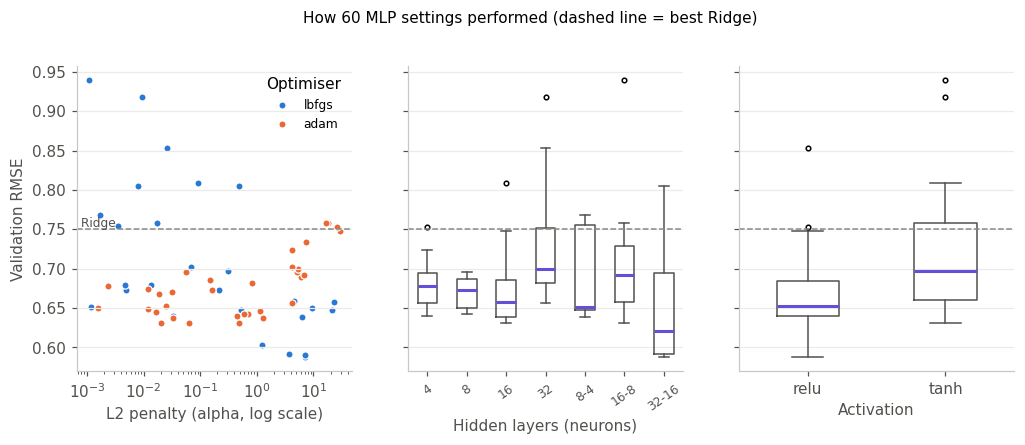

,hyperparameter,effect_on_cv_rmse,measure
0,alpha (L2 penalty),-1.279e-01,Spearman rho
1,learning rate,5.224e-03,Spearman rho
2,architecture,7.926e-02,range of medians
3,activation,4.432e-02,range of medians
4,optimiser,7.366e-04,range of medians


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
ref = ridge_log["cv_rmse"].min()
for solver, col in [("lbfgs", C["blue"]), ("adam", C["orange"])]:
    d = search_log[search_log["solver"] == solver]
    axes[0].scatter(d["alpha"], d["cv_rmse"], s=22, color=col, label=solver, edgecolor="white", linewidth=0.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("L2 penalty (alpha, log scale)")
axes[0].set_ylabel("Validation RMSE"); axes[0].legend(frameon=False, title="Optimiser", fontsize=8)

archs = ["4", "8", "16", "32", "8-4", "16-8", "32-16"]
vals = [search_log.loc[search_log["architecture"] == a, "cv_rmse"].to_numpy() for a in archs]
axes[1].boxplot(vals, tick_labels=archs, widths=0.5, medianprops={"color": C["violet"], "lw": 2},
                boxprops={"color": C["ink2"]}, whiskerprops={"color": C["ink2"]},
                capprops={"color": C["ink2"]}, flierprops={"markersize": 3})
axes[1].set_xlabel("Hidden layers (neurons)")
axes[1].tick_params(axis="x", labelsize=8, rotation=35)

acts = ["relu", "tanh"]
axes[2].boxplot([search_log.loc[search_log["activation"] == a, "cv_rmse"].to_numpy() for a in acts],
                tick_labels=acts, widths=0.45, medianprops={"color": C["violet"], "lw": 2},
                boxprops={"color": C["ink2"]}, whiskerprops={"color": C["ink2"]},
                capprops={"color": C["ink2"]}, flierprops={"markersize": 3})
axes[2].set_xlabel("Activation")
for ax in axes:
    ax.axhline(ref, color=C["grey"], ls="--", lw=1)
    ax.grid(axis="x", visible=False)
axes[0].text(axes[0].get_xlim()[0], ref, " Ridge", va="bottom", fontsize=8, color=C["ink2"])
fig.suptitle(f"How {N_TRIALS_FULL} MLP settings performed (dashed line = best Ridge)", fontsize=10, y=1.02)
save_fig(fig, "fig4_tuning_study"); plt.show()

# Simple importance of each hyperparameter: rank correlation with CV RMSE / spread across levels
imp = pd.DataFrame({
    "hyperparameter": ["alpha (L2 penalty)", "learning rate", "architecture", "activation", "optimiser"],
    "effect_on_cv_rmse": [
        stats.spearmanr(search_log["alpha"], search_log["cv_rmse"]).statistic,
        stats.spearmanr(search_log["learning_rate_init"], search_log["cv_rmse"]).statistic,
        search_log.groupby("architecture")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
        search_log.groupby("activation")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
        search_log.groupby("solver")["cv_rmse"].median().pipe(lambda s: s.max() - s.min()),
    ],
    "measure": ["Spearman rho", "Spearman rho", "range of medians", "range of medians", "range of medians"]})
save_table(imp, "table4_hyperparameter_effects")
imp

### 8b. Seed sensitivity: is the network stable?

A neural network starts from random weights, so a different seed can give a different model. Here each model is retrained with 10 different seeds, keeping the hyperparameters chosen in Section 7, and the spread of out-of-sample R² is measured. Ridge has no randomness, so its spread is zero. As a common way to stabilise a network, the table also shows the **average of the 10 MLPs (a seed ensemble)**.

In [17]:
seed_rows, mlp_seed_preds = [], []
for s in SEEDS:
    p, _ = walk_forward(ALL_FEATS, models=["RandomForest", "XGBoost", "MLP"], seed=s, fixed_params=wf_params)
    sc = score(p, ["RandomForest", "XGBoost", "MLP"])
    sc["seed"] = s
    seed_rows.append(sc)
    mlp_seed_preds.append(p["MLP"].to_numpy())
seed_scores = pd.concat(seed_rows, ignore_index=True)

ens = wf_pred[["ticker", "year", "log_pb", "train_mean"]].copy()
ens["MLP seed-ensemble"] = np.mean(mlp_seed_preds, axis=0)
ens_score = score(ens, ["MLP seed-ensemble"])

seed_summary = (seed_scores.groupby("model")["oos_r2"].agg(["mean", "std", "min", "max"])
                .reindex(["RandomForest", "XGBoost", "MLP"]))
r2_ridge = wf_scores.set_index("model").at["Ridge", "oos_r2"]
seed_summary.loc["Ridge"] = [r2_ridge, 0.0, r2_ridge, r2_ridge]
seed_summary.loc["MLP seed-ensemble"] = [ens_score["oos_r2"].iloc[0], np.nan, np.nan, np.nan]
seed_summary = seed_summary.rename(columns=lambda c: f"oos_r2_{c}")
save_table(seed_summary.reset_index(names="model"), "table5_seed_sensitivity")
save_table(seed_scores, "seed_scores_all")
seed_summary

,oos_r2_mean,oos_r2_std,oos_r2_min,oos_r2_max
model,,,,
RandomForest,0.641,0.002,0.638,0.644
XGBoost,0.678,0.004,0.671,0.684
MLP,0.687,0.007,0.677,0.697
Ridge,0.564,0.000,0.564,0.564
MLP seed-ensemble,0.705,NaN,NaN,NaN


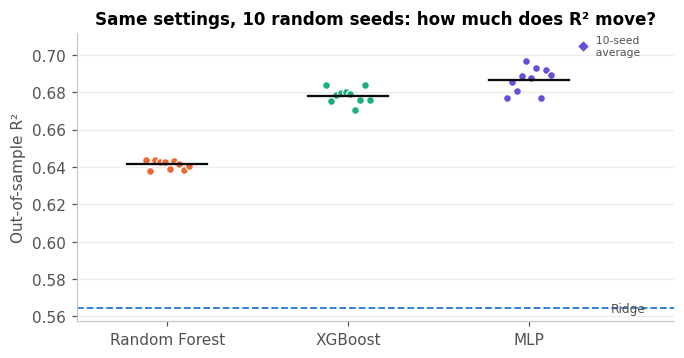

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for k, m in enumerate(["RandomForest", "XGBoost", "MLP"]):
    v = seed_scores.loc[seed_scores["model"] == m, "oos_r2"].to_numpy()
    jitter = np.linspace(-0.12, 0.12, len(v))
    ax.scatter(k + jitter, v, s=26, color=MODEL_COLORS[m], edgecolor="white", linewidth=0.8, zorder=2)
    ax.plot([k - 0.22, k + 0.22], [v.mean()] * 2, color=C["ink"], lw=1.5, zorder=3)
ax.axhline(seed_summary.at["Ridge", "oos_r2_mean"], color=MODEL_COLORS["Ridge"], ls="--", lw=1.2)
ax.text(2.45, seed_summary.at["Ridge", "oos_r2_mean"], "Ridge", va="center", fontsize=8, color=C["ink2"])
ax.scatter(2.3, seed_summary.at["MLP seed-ensemble", "oos_r2_mean"], marker="D", s=34,
           color=C["violet"], edgecolor="white", zorder=3)
ax.text(2.33, seed_summary.at["MLP seed-ensemble", "oos_r2_mean"], "  10-seed\n  average", fontsize=7,
        va="center", color=C["ink2"])
ax.set_xticks(range(3), ["Random Forest", "XGBoost", "MLP"]); ax.set_xlim(-0.5, 2.8)
ax.set_ylabel("Out-of-sample R²"); ax.grid(axis="x", visible=False)
ax.set_title("Same settings, 10 random seeds: how much does R² move?")
save_fig(fig, "fig5_seed_sensitivity"); plt.show()

### 8c. Ablation: which inputs carry the signal?

Each model is re-run three times: with fundamentals only, with market inputs only, and with both. If the fundamentals-only score is close to the combined one, valuations are mostly explained by the company's economics and not by recent price behaviour.

In [19]:
abl_rows = []
for set_name, feats in FEATURE_SETS.items():
    if set_name == "Fundamentals + market":
        sc = wf_scores[wf_scores["model"].isin(["Ridge", "XGBoost", "MLP"])].copy()
    else:
        p, _ = walk_forward(feats, models=["Ridge", "XGBoost", "MLP"], n_trials=N_TRIALS_ABL)
        sc = score(p, ["Ridge", "XGBoost", "MLP"])
    sc["inputs"] = set_name
    abl_rows.append(sc)
ablation = pd.concat(abl_rows).pivot(index="inputs", columns="model", values="oos_r2")[["Ridge", "XGBoost", "MLP"]]
ablation = ablation.reindex(list(FEATURE_SETS))
save_table(ablation.reset_index(), "table6_ablation_oos_r2")
ablation

model,Ridge,XGBoost,MLP
inputs,,,
Fundamentals only,0.529,0.643,0.630
Market only,0.064,0.085,0.053
Fundamentals + market,0.564,0.683,0.701


### 8d. What is the model paying attention to?

Both final models are fitted on all years with their best full-sample settings.

- **Ridge coefficients** can be read directly: the change in log P/B for a one-standard-deviation change in each input.
- **Permutation importance** works for any model: shuffle one input and measure how much worse the fit gets.
- **Partial dependence** shows how the MLP's fair P/B changes as one input moves, with everything else held at its observed values.

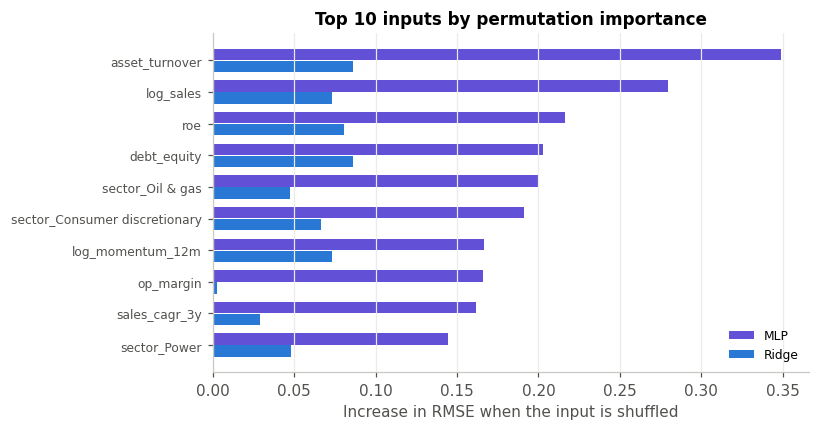

,ridge_coef_per_sd,ridge_perm_importance,mlp_perm_importance
asset_turnover,0.226,8.617e-02,0.349
log_sales,-0.209,7.351e-02,0.279
roe,0.217,8.033e-02,0.216
debt_equity,0.229,8.634e-02,0.203
sector_Oil & gas,-0.167,4.776e-02,0.200
sector_Consumer discretionary,0.197,6.632e-02,0.191
log_momentum_12m,0.209,7.336e-02,0.167
op_margin,0.039,2.394e-03,0.166
sales_cagr_3y,0.129,2.924e-02,0.162
sector_Power,-0.166,4.801e-02,0.145


In [20]:
final_mlp = build("MLP", best_full).fit(data[ALL_FEATS], data["log_pb"])
final_ridge = build("Ridge", ridge_full).fit(data[ALL_FEATS], data["log_pb"])

coef = pd.Series(final_ridge[-1].coef_, index=ALL_FEATS)
pi = permutation_importance(final_mlp, data[ALL_FEATS], data["log_pb"], n_repeats=30,
                            random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
pi_r = permutation_importance(final_ridge, data[ALL_FEATS], data["log_pb"], n_repeats=30,
                              random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
interp = pd.DataFrame({"ridge_coef_per_sd": coef,
                       "ridge_perm_importance": pi_r.importances_mean,
                       "mlp_perm_importance": pi.importances_mean}).sort_values("mlp_perm_importance", ascending=False)
save_table(interp.reset_index(names="feature"), "table7_interpretability")

top = interp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(top))
ax.barh(y + 0.19, top["mlp_perm_importance"], height=0.36, color=C["violet"], label="MLP")
ax.barh(y - 0.19, top["ridge_perm_importance"], height=0.36, color=C["blue"], label="Ridge")
ax.set_yticks(y, top.index, fontsize=8)
ax.set_xlabel("Increase in RMSE when the input is shuffled")
ax.set_title("Top 10 inputs by permutation importance")
ax.legend(frameon=False, fontsize=8); ax.grid(axis="y", visible=False)
save_fig(fig, "fig6_importance"); plt.show()
interp

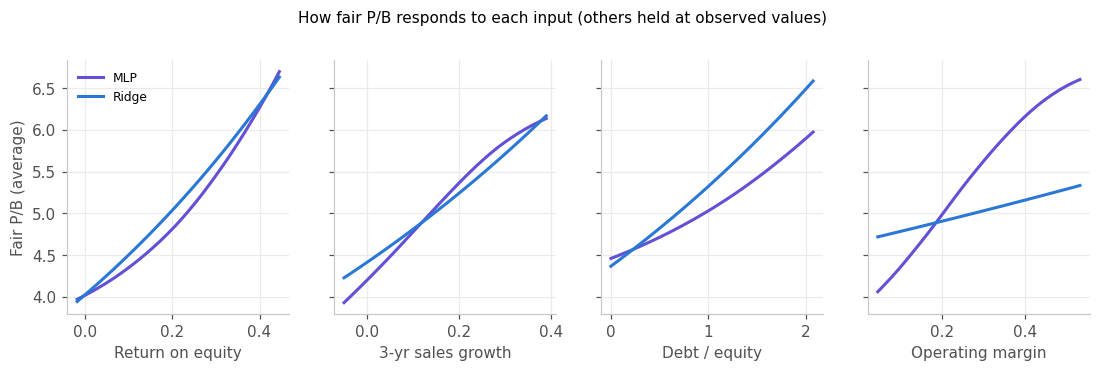

In [21]:
pd_feats = ["roe", "sales_cagr_3y", "debt_equity", "op_margin"]
labels = {"roe": "Return on equity", "sales_cagr_3y": "3-yr sales growth",
          "debt_equity": "Debt / equity", "op_margin": "Operating margin"}
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, f in zip(axes, pd_feats):
    for model, col in [(final_mlp, C["violet"]), (final_ridge, C["blue"])]:
        r = partial_dependence(model, data[ALL_FEATS], [f], grid_resolution=30,
                               percentiles=(0.05, 0.95), kind="average")
        ax.plot(r["grid_values"][0], np.exp(r["average"][0]), color=col, lw=2)
    ax.set_xlabel(labels[f])
axes[0].set_ylabel("Fair P/B (average)")
axes[0].legend(["MLP", "Ridge"], frameon=False, fontsize=8)
fig.suptitle("How fair P/B responds to each input (others held at observed values)", fontsize=10, y=1.03)
save_fig(fig, "fig7_partial_dependence"); plt.show()

### 8e. Can the model value a company it has never seen?

The walk-forward test predicts *next year* for companies the model already knows from earlier years. Valuing an unlisted business is harder: the company is new to the model. Here companies are split into five groups; each group is predicted by a model trained only on the other four, so no company's own history is used to predict it. Hyperparameters are the full-sample settings from Section 8a, and the folds are fixed (no random shuffle).

In [22]:
from sklearn.model_selection import GroupKFold
xgb_full, _ = tune("XGBoost", data, ALL_FEATS)
gkf = GroupKFold(n_splits=5)
lco = data[["code", "year", "log_pb"]].copy()
for name, params in [("Ridge", ridge_full), ("XGBoost", xgb_full), ("MLP", best_full)]:
    lco[name] = np.nan
    for tr_idx, te_idx in gkf.split(data, groups=data["code"]):
        m = build(name, params).fit(data.iloc[tr_idx][ALL_FEATS], data.iloc[tr_idx]["log_pb"])
        lco.loc[lco.index[te_idx], name] = m.predict(data.iloc[te_idx][ALL_FEATS])
sst = ((lco["log_pb"] - lco["log_pb"].mean()) ** 2).sum()
lco_scores = pd.DataFrame([{"model": n, "r2_unseen_companies": 1 - ((lco["log_pb"] - lco[n]) ** 2).sum() / sst,
                            "rmse": rmse(lco["log_pb"], lco[n])} for n in ["Ridge", "XGBoost", "MLP"]])
save_table(lco_scores, "table10_unseen_companies")
lco_scores

,model,r2_unseen_companies,rmse
0,Ridge,0.560,0.676
1,XGBoost,0.610,0.637
2,MLP,0.577,0.663


## 9. Investment test: does mispricing predict the next 12 months' return?

Each 30 June from 2019 to 2025, a stock's **mispricing** is its actual log P/B minus the model's out-of-sample fair value; a negative value means it looks cheap for its fundamentals. With 110–140 stocks a year, stocks are sorted into **five equal groups (quintiles)** by cheapness. For each year the test reports:
- the **rank correlation (IC)** between cheapness and the next 12-month price return;
- the average return of the **cheapest and most expensive quintiles**, against the equal-weighted average of all stocks and the NIFTY 50.

In [23]:
bt_rows = []
for model in ["Ridge", "MLP"]:
    for yr in BACKTEST_YEARS:
        d = wf_pred[(wf_pred["year"] == yr)].dropna(subset=["fwd_return_12m"]).copy()
        d["cheapness"] = -(d["log_pb"] - d[model])
        d["quintile"] = pd.qcut(d["cheapness"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
        q = d.groupby("quintile")["fwd_return_12m"].mean()
        bt_rows.append({"model": model, "year": yr, "n": len(d),
                        "ic": stats.spearmanr(d["cheapness"], d["fwd_return_12m"]).statistic,
                        "cheapest_q": q.loc[1], "q2": q.loc[2], "q3": q.loc[3], "q4": q.loc[4],
                        "dearest_q": q.loc[5],
                        "equal_weight_all": d["fwd_return_12m"].mean(),
                        "nifty50": d["nifty_fwd_12m"].iloc[0]})
backtest = pd.DataFrame(bt_rows)
backtest["cheap_minus_dear"] = backtest["cheapest_q"] - backtest["dearest_q"]
summary = backtest.groupby("model")[["ic", "cheapest_q", "q2", "q3", "q4", "dearest_q", "cheap_minus_dear",
                                      "equal_weight_all", "nifty50"]].mean()
summary["ic_t_stat"] = backtest.groupby("model")["ic"].apply(lambda s: s.mean() / (s.std(ddof=1) / np.sqrt(len(s))))
summary["years_ic_positive"] = backtest.groupby("model")["ic"].apply(lambda s: int((s > 0).sum()))
save_table(backtest, "table8_backtest_by_year")
save_table(summary.reset_index(), "table9_backtest_summary")
display(backtest.round(3))
summary.round(3)

,model,year,n,ic,cheapest_q,q2,q3,q4,dearest_q,equal_weight_all,nifty50,cheap_minus_dear
0,Ridge,2019,112,-0.219,0.196,-0.123,-0.166,-0.010,0.042,-0.010,-0.126,0.154
1,Ridge,2020,114,0.037,0.925,1.055,0.711,0.879,1.214,0.959,0.526,-0.289
2,Ridge,2021,123,-0.121,-0.007,0.018,0.099,0.064,0.144,0.064,0.004,-0.151
3,Ridge,2022,126,0.269,0.585,0.279,0.388,0.241,0.204,0.338,0.216,0.381
4,Ridge,2023,133,0.335,1.363,0.850,0.649,0.628,0.746,0.849,0.251,0.617
5,Ridge,2024,132,0.040,0.050,0.028,0.055,0.130,-0.020,0.048,0.063,0.071
6,Ridge,2025,139,-0.106,0.016,0.012,-0.000,0.028,0.165,0.044,-0.065,-0.149
7,MLP,2019,112,-0.326,-0.173,0.168,-0.069,-0.021,0.049,-0.010,-0.126,-0.222
8,MLP,2020,114,-0.027,0.987,0.868,0.910,1.010,1.018,0.959,0.526,-0.031
9,MLP,2021,123,-0.140,0.060,0.015,0.001,0.067,0.174,0.064,0.004,-0.114


,ic,cheapest_q,q2,q3,q4,dearest_q,cheap_minus_dear,equal_weight_all,nifty50,ic_t_stat,years_ic_positive
model,,,,,,,,,,,
MLP,-0.060,0.351,0.342,0.261,0.336,0.347,0.003,0.328,0.124,-0.862,2
Ridge,0.034,0.447,0.303,0.248,0.280,0.356,0.091,0.328,0.124,0.434,4


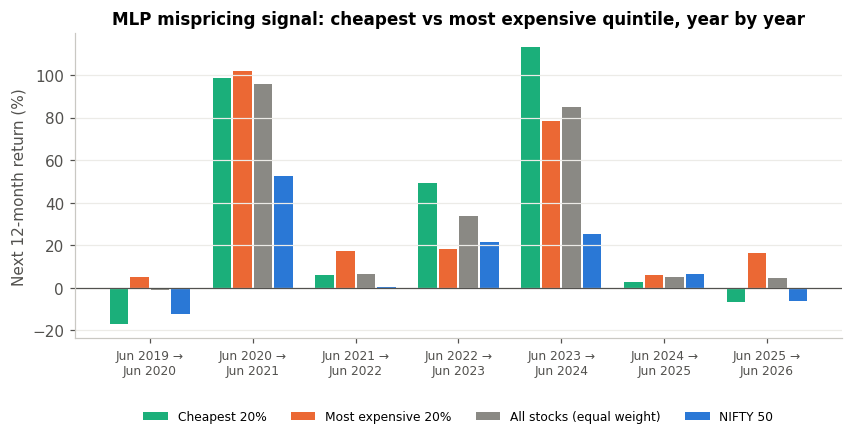

In [24]:
d = backtest[backtest["model"] == "MLP"].set_index("year")
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(d)); w = 0.2
for k, (c, lab, col) in enumerate([("cheapest_q", "Cheapest 20%", C["aqua"]),
                                    ("dearest_q", "Most expensive 20%", C["orange"]),
                                    ("equal_weight_all", "All stocks (equal weight)", C["grey"]),
                                    ("nifty50", "NIFTY 50", C["blue"])]):
    ax.bar(x + (k - 1.5) * w, d[c] * 100, width=w - 0.02, color=col, label=lab)
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_xticks(x, [f"Jun {y} →\nJun {y+1}" for y in d.index], fontsize=8)
ax.set_ylabel("Next 12-month return (%)")
ax.set_title("MLP mispricing signal: cheapest vs most expensive quintile, year by year")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="x", visible=False)
save_fig(fig, "fig8_backtest"); plt.show()

## 10. Business use: a fair P/B for an unlisted company

The model can give a starting valuation multiple for a private company from its fundamentals. Market inputs don't exist for an unlisted firm, so they're set to the sample median, and inputs outside the range the model has seen are set to the nearest observed value. The example is **illustrative**: replace the numbers with a real company's figures. Section 8e shows how accurate the model is for companies it hasn't seen, and a small private firm would need a further discount for size and illiquidity, which this model doesn't capture.

In [25]:
def fair_value(sector, book_value_cr, **fundamentals):
    row = {f: np.nan for f in ALL_FEATS}
    row.update({m: data[m].median() for m in MKT_FEATS})
    clipped = []
    for k, v in fundamentals.items():
        lo, hi = data[k].min(), data[k].max()
        if not lo <= v <= hi:
            clipped.append(k)
        row[k] = float(np.clip(v, lo, hi))
    if clipped:
        print("Inputs outside the training range, set to the nearest observed value:", clipped)
    for s in SECTORS:
        row[f"sector_{s}"] = float(s == sector)
    X = pd.DataFrame([row])[ALL_FEATS]
    out = {}
    for name, model in [("Ridge", final_ridge), ("MLP", final_mlp)]:
        pb_ = float(np.exp(model.predict(X)[0]))
        out[name] = {"fair_P/B": round(pb_, 2), "implied_equity_value_cr": round(pb_ * book_value_cr, 1)}
    return pd.DataFrame(out).T

example = fair_value("FMCG", book_value_cr=3000, roe=0.18, op_margin=0.10, sales_cagr_3y=0.12,
                     debt_equity=0.4, log_interest_cover=np.log1p(8), asset_turnover=1.8,
                     payout=0.3, cash_conversion=0.9, roe_volatility_3y=0.03, log_sales=np.log(15000))
example

,fair_P/B,implied_equity_value_cr
Ridge,9.34,28021.5
MLP,10.09,30273.0


## 11. Reproducibility fingerprint

The key result tables are hashed into one fingerprint. Rerunning the notebook on the same frozen data and library versions must give the same fingerprint, and the cell below says whether it does. Library versions are saved in `outputs/environment.json`.

In [26]:
key_tables = {"walkforward": wf_scores, "rmse_by_year": by_year.reset_index(),
              "search": search_log.drop(columns="hidden_layer_sizes"), "seeds": seed_summary.reset_index(),
              "ablation": ablation.reset_index(), "interp": interp.reset_index(),
              "unseen": lco_scores, "backtest": backtest}
h = hashlib.sha256()
for k in sorted(key_tables):
    h.update(k.encode()); h.update(key_tables[k].round(10).to_csv(index=False).encode())
fingerprint = h.hexdigest()

fp_file = OUT / "fingerprint.txt"
previous = fp_file.read_text().strip() if fp_file.exists() else None
fp_file.write_text(fingerprint)
print("Results fingerprint:", fingerprint)
if previous is None:
    print("First run: fingerprint saved. Rerun the notebook to confirm it reproduces.")
elif previous == fingerprint:
    print("IDENTICAL to previous run.")
else:
    print("DIFFERENT from previous run:", previous, "\nCheck data checksums and outputs/environment.json.")

Results fingerprint: cc76887faf6698658642e512b1dd01c580ae89ef1fbefd8db667f83f889be888
First run: fingerprint saved. Rerun the notebook to confirm it reproduces.


## Outputs written

- `outputs/tables/`: every table above as CSV (`table1` to `table10`, plus the modelling table, predictions and search log)
- `outputs/figures/`: figures `fig1` to `fig8` as PNG
- `outputs/environment.json`: the exact library versions used
- `outputs/fingerprint.txt`: the results fingerprint

**Data notes for the report.** The universe is today's NIFTY 200 non-financial companies, so some survivorship bias remains even with the ₹5,000 crore size rule. Market cap is June's monthly average, and returns are price returns that exclude dividends.